# Domain Conditional Pointwise Mutual Interest

This is a demo of how we can apply DC-PMI to multiple choice answer prediction following Holtzman et al. 2021.

In [1]:
import os

import torch
from torch.testing import assert_close
from dotenv import load_dotenv
from huggingface_hub import login
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset
import matplotlib.pyplot as plt
import numpy as np

In [2]:
load_dotenv("secret.env")
login()

In [3]:
MODEL = "google/gemma-3-1b-it"
device = "cuda"
tokenizer = AutoTokenizer.from_pretrained(MODEL)
model = AutoModelForCausalLM.from_pretrained(
    MODEL,
    dtype=torch.bfloat16,
).to(device)
model.eval()
dataset = load_dataset("tau/commonsense_qa", split="validation")

Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

---

## Example question

In [4]:
q = dataset[2]
q

{'id': 'b8c0a4703079cf661d7261a60a1bcbff',
 'question': 'Where would you find magazines along side many other printed works?',
 'question_concept': 'magazines',
 'choices': {'label': ['A', 'B', 'C', 'D', 'E'],
  'text': ['doctor', 'bookstore', 'market', 'train station', 'mortuary']},
 'answerKey': 'B'}

In [5]:
q_token_ids = tokenizer(q['question']+"\n\n", return_tensors="pt").input_ids.to(device)
q_token_ids.shape

torch.Size([1, 14])

In [6]:
outputs = model(q_token_ids)
outputs

CausalLMOutputWithPast(loss=None, logits=tensor([[[-14.1875,  -1.1172,   4.6875,  ..., -14.6250, -14.6875, -14.6250],
         [-17.1250,  -2.2344,  -1.6172,  ..., -18.3750, -18.3750, -18.1250],
         [-17.0000,  -3.5781,  -1.5859,  ..., -18.0000, -18.0000, -17.8750],
         ...,
         [-18.7500,  -0.2969,   0.5391,  ..., -20.6250, -20.6250, -20.5000],
         [-14.0625,   0.2930,  -2.0000,  ..., -14.7500, -14.8125, -14.6875],
         [ -8.1875,  -1.0703,   0.9883,  ...,  -9.0000,  -9.0625,  -8.8750]]],
       device='cuda:0', dtype=torch.bfloat16, grad_fn=<UnsafeViewBackward0>), past_key_values=DynamicCache(layers=[DynamicSlidingWindowLayer, DynamicSlidingWindowLayer, DynamicSlidingWindowLayer, DynamicSlidingWindowLayer, DynamicSlidingWindowLayer, DynamicLayer, DynamicSlidingWindowLayer, DynamicSlidingWindowLayer, DynamicSlidingWindowLayer, DynamicSlidingWindowLayer, DynamicSlidingWindowLayer, DynamicLayer, DynamicSlidingWindowLayer, DynamicSlidingWindowLayer, DynamicSliding

In [7]:
outputs.logits.shape

torch.Size([1, 14, 262144])

In [8]:
# what comes after the last token?
last_logits = outputs.logits[0, -1]
last_logits

tensor([-8.1875, -1.0703,  0.9883,  ..., -9.0000, -9.0625, -8.8750],
       device='cuda:0', dtype=torch.bfloat16, grad_fn=<SelectBackward0>)

In [9]:
values, indices = torch.topk(last_logits, 20)
for logit, i in zip(values, indices):
    print(f"{repr(tokenizer.decode(i))}: {logit:.2f}")

'A': 19.38
'a': 17.12
'This': 16.25
'**': 15.94
'The': 15.12
'(': 15.00
'Answer': 13.94
'*': 13.94
'**(': 13.94
'Here': 13.50
'You': 12.88
'Answers': 12.88
'Your': 12.81
'Okay': 12.62
'b': 12.19
'---': 12.19
'What': 11.75
'...': 11.62
'<': 11.50
'I': 11.44


In [10]:
for choice in q['choices']['text']:
    ids = tokenizer(choice).input_ids
    ids_no_special = tokenizer(choice, add_special_tokens=False).input_ids
    print(f"{choice}: {ids}, {ids_no_special}")

doctor: [2, 29324], [29324]
bookstore: [2, 3070, 6457], [3070, 6457]
market: [2, 16350], [16350]
train station: [2, 4909, 6410], [4909, 6410]
mortuary: [2, 48147, 4979], [48147, 4979]


---

## Compare multiple choice classification methods

### LM (answers excluded)

In [ ]:
# Question: ... The correct answer is: bookstore 

def choice_prob(prompt_ids, choice):
    print(choice)
    choice_ids = tokenizer(choice, add_special_tokens=False, return_tensors="pt").input_ids[0].to(device)
    ids = torch.cat((prompt_ids, choice_ids)) # Question: ... The correct answer is: bookstore
    out_logits = model(ids.unsqueeze(0)).logits[0]
    out_probs = out_logits.softmax(1)
    assert_close(out_probs[0, :].sum().item(), 1.0)
    total_prob = 1.0
    for i, token_id in enumerate(choice_ids):
        choice_prob = out_probs[len(prompt_ids)-1+i][token_id]
        print(f"{token_id} {repr(tokenizer.decode(token_id))}: {choice_prob:.2e}")
        total_prob *= choice_prob.item()
    print(f"{total_prob:.2e}")
    return total_prob

def evaluate_choices(prompt, choices):
    prompt_ids = tokenizer(prompt, return_tensors="pt").input_ids[0].to(device)
    return [choice_prob(prompt_ids, choice) for choice in choices]

In [18]:
prompt = f"""Question: {q['question']}
The correct answer is: """
print(prompt)
mc_answers_excluded = evaluate_choices(prompt, q['choices']['text'])

Question: Where would you find magazines along side many other printed works?
The correct answer is: 
doctor
29324 'doctor': 5.20e-14
5.20e-14
bookstore
3070 'book': 2.17e-12
6457 'store': 5.35e-01
1.16e-12
market
16350 'market': 4.88e-14
4.88e-14
train station
4909 'train': 7.68e-14
6410 ' station': 2.38e-01
1.83e-14
mortuary
48147 'mort': 4.44e-14
4979 'uary': 5.61e-04
2.49e-17


### LM (answers included)

In [13]:
prompt = f"""Question: {q['question']}
Possible answers: {', '.join(q['choices']['text'])}
The correct answer is: """
mc_answers_included = evaluate_choices(prompt, q['choices']['text'])

doctor
29324 'doctor': 3.67e-12
3.67e-12
bookstore
3070 'book': 2.28e-09
6457 'store': 1.00e+00
2.28e-09
market
16350 'market': 1.21e-11
1.21e-11
train station
4909 'train': 4.91e-14
6410 ' station': 1.00e+00
4.91e-14
mortuary
48147 'mort': 1.03e-15
4979 'uary': 1.00e+00
1.03e-15


### DC-PMI

In [14]:
prompt = f"""The correct answer is: """
pmi_prior = evaluate_choices(prompt, q['choices']['text'])

doctor
29324 'doctor': 2.69e-11
2.69e-11
bookstore
3070 'book': 4.39e-11
6457 'store': 1.43e-03
6.29e-14
market
16350 'market': 9.32e-11
9.32e-11
train station
4909 'train': 1.25e-10
6410 ' station': 2.67e-04
3.33e-14
mortuary
48147 'mort': 1.42e-11
4979 'uary': 9.82e-05
1.40e-15


In [15]:
dc_pmi = np.array(mc_answers_excluded) / np.array(pmi_prior)
dc_pmi

array([1.92840190e-03, 1.84861647e+01, 5.24009146e-04, 5.50208551e-01,
       1.78398058e-02])

### Comparison

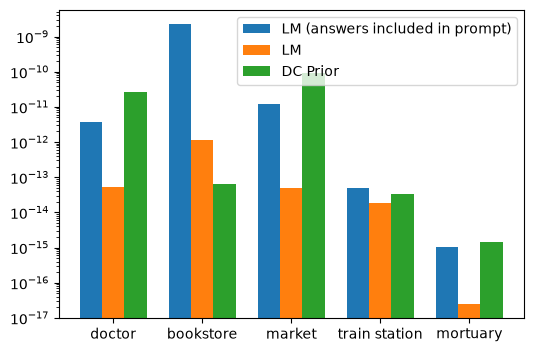

In [16]:
choice_probs = {
    "LM (answers included in prompt)": mc_answers_included,
    "LM": mc_answers_excluded,
    "DC Prior": pmi_prior,
}

fig, ax = plt.subplots(figsize=(6,4))
ax.set_yscale("log")
ax.grouped_bar(choice_probs, tick_labels=q['choices']['text'], group_spacing=1)
ax.legend()
fig.show()

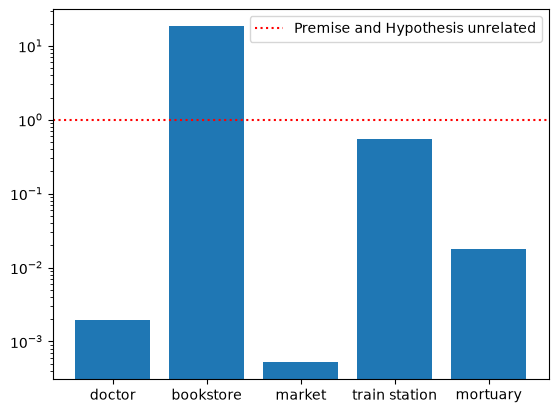

In [17]:
fig, ax = plt.subplots()
ax.bar(q['choices']['text'], dc_pmi)
ax.set_yscale('log')
ax.axhline(1.0, label='Premise and Hypothesis unrelated', linestyle=':', color='red')
ax.legend()
fig.show()